# Which intrinsic-alignment terms make the aperture signal?

The observed shear of a galaxy contains gravitational lensing, written $G$, and
the galaxy's intrinsic shape, written $I$. The three factors in an aperture
moment can therefore form eight ordered combinations; $GGI$, for example, has
an intrinsic shape on its third source leg. A second classification asks what
produces that intrinsic shape: linear alignment, density weighting, tidal
torque, or velocity shear. The two classifications answer different physical
questions, and this notebook keeps them separate.

The notebook follows the operator and placement comparisons in Figures 5 and 6
of [Gomes et al., arXiv:2601.09133](https://arxiv.org/html/2601.09133v1), whose
physical calculation and original fastnc implementation these curves build on.
The configured Y3 sources, finite triangle window and grids stay demonstration
assumptions, so the curves are not a digitized or numerically matched
reproduction of those figures. The companion
[IA Fisher notebook](notes/intrinsic_alignments/EXAMPLE_FISHER_IA.ipynb) tests local parameter separation
with the joint covariance.

**Model and data.** The run below evaluates one numbered Cobaya example and reports two
source triples:

| Choice | Value |
| --- | --- |
| Cobaya example | `EXAMPLE_EVALUATE4.yaml` (TATT), at its `sampler.evaluate.override` point |
| Source triples | 111 and 134 (one-based labels; `[0, 0, 0]` and `[0, 2, 3]` in code) |
| Velocity-shear amplitude | $C_t/C_1=2.5$ |
| Figures | `components_111.png` and `components_134.png` in `chains/ia_components/` |
| Threads | one BLAS worker; OpenMP capped at four |

Words used throughout:

- **TATT**, tidal alignment and tidal torquing: the intrinsic-alignment model
  whose linear shapes carry the amplitude $A_1$ and whose quadratic tidal
  shapes carry the amplitude $A_2$, with density weighting $b_\mathrm{TA}$.
- An **aperture moment** $\langle M_\mathrm{ap}^3(R)\rangle$ integrates three
  shear fields with a compensated filter of radius $R$; each of its three legs
  is a source bin.
- A **placement** names which legs are intrinsic: $GGG$ is pure lensing, $GGI$
  has one intrinsic shape, and so on through $III$ with three.
- An **operator** names what produces an intrinsic shape: linear alignment
  (coefficient $C_1$), density weighting ($C_{1\delta}=b_\mathrm{TA}C_1$),
  tidal torque ($C_2$), or velocity shear ($C_t$, the velocity-shear
  amplitude).

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
os.environ["OMP_THREAD_LIMIT"] = "4"
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
from cobaya.yaml import yaml_load_file
import cosmolike_des_3pcf_notebook_wrappers as nw

blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 1. Keep the physical operators distinct

The tensor calculation uses the coefficients $C_1$, $C_2$, and
$C_{1\delta}=b_\mathrm{TA}C_1$. Its density-shaped vertex carries the
coefficient $C_{1\delta}-2C_2/3$, so a tidal-torque contribution contains both
the quadratic-shaped vertex and the $-2C_2/3$ part of the density-shaped
vertex, while the density-weighting contribution contains only $C_{1\delta}$.
Every higher-order term keeps the linear shapes on its other intrinsic legs;
dropping those shapes would erase $GII$ and $III$ incorrectly.

The code expands the nonlinear-alignment baseline from
$(G_1+I_1)(G_2+I_2)(G_3+I_3)$ on its original source-kernel grid, and every
signed baseline component uses the same positive $GGG$ interpolation scale.
Higher-order terms use the same triangle grids and integration weights, and the
code also evaluates the complete calculation independently of the sum as a
check.

The run reports source triples 111 and 134 with the existing Y3 demonstration
configuration, including the recorded source clipping and its finite triangle
window. It sets $C_t/C_1=2.5$, where $C_t$ is the velocity-shear amplitude, so
the velocity-shear operator contributes visibly. The numerical velocity-shear
vertex follows the active upstream implementation; the velocity-shear vertex
equations of Gomes et al. (arXiv:2601.09133) do not agree with that vertex in
simple limits, and that discrepancy must be resolved before claiming an
independent reproduction of the paper's velocity-shear curves. The TATT terms
have a separate analytic equilateral test.

The next cell runs the decomposition: `nw.configure` selects the TATT
example, and `nw.map3_components` returns the five-operator-by-eight-placement
split of the requested Map3 rows. Its two checks confirm that the signed
pieces add up to an independently computed total, and that the four operators
the likelihood scores (velocity shear excluded, since the likelihood fixes
$C_t=0$) reproduce the likelihood's own Map3 rows.

In [3]:
# The numbered TATT example: EXAMPLE_EVALUATE4.yaml samples DES_A1_1,
# DES_A1_2, DES_A2_1, DES_A2_2 and DES_BTA_1, so every IA operator has a
# nonzero amplitude. Its fiducial point
# differs from the project fiducial (EXAMPLE_EVALUATE3) only in the
# tidal-torquing amplitude A2 = [DES_A2_1, DES_A2_2] and the density
# weighting DES_BTA_1.
nw.configure(yaml="EXAMPLE_EVALUATE4.yaml", threads=4)
fiducial = yaml_load_file(str(PROJECT / "EXAMPLE_EVALUATE4.yaml"))["sampler"]["evaluate"]["override"]

report = nw.map3_components(
    triplets=np.array([[0, 0, 0], [0, 2, 3]], dtype=np.int32),
    velocity_shear=2.5,
    A2=[fiducial["DES_A2_1"], fiducial["DES_A2_2"]],
    BTA=fiducial["DES_BTA_1"],
)
components = report["components"]
scale = np.max(np.abs(components["total"]))
closure = np.max(np.abs(components["closure"])) / scale
print("IA parameters:", report["ia"])
print("Maximum sum error / maximum absolute total:", closure)
np.testing.assert_allclose(
    np.sum(components["values"], axis=(0, 1)), components["total"],
    rtol=2.e-10, atol=scale * 2.e-12,
)

# The likelihood scores ct = 0, and C_t enters only the velocity-shear
# operator (index 4), so the other four operators must add up to the Map3
# rows the likelihood itself predicted at this point.
without_velocity_shear = np.sum(components["values"][:4], axis=(0, 1))
prediction = report["prediction"]
difference = np.max(np.abs(without_velocity_shear - prediction))
print("Maximum difference from the likelihood's Map3 rows / maximum absolute row:",
      difference / np.max(np.abs(prediction)))
np.testing.assert_allclose(
    without_velocity_shear, prediction,
    rtol=2.e-10, atol=np.max(np.abs(prediction)) * 2.e-12,
)


[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


IA parameters: {'a1': -0.33, 'eta1': 2.81, 'a2': 0.65, 'eta2': 1.69, 'bta': 0.91, 'c1rho': 0.01389, 'zpivot': 0.62, 'power_mode': 2, 'ct': 2.5, 'fb': 0.0, 'feedback_amplitude': 0.0, 'ct_mode': 0}
Maximum sum error / maximum absolute total: 1.2118139687295272e-14
Maximum difference from the likelihood's Map3 rows / maximum absolute row: 1.1549234447404735e-14


## 2. Read the signed contributions

The plot divides each curve by the gravity-only aperture moment at the same
radius and source triple. A negative value opposes the gravitational signal; it
is not an invalid power spectrum. The black curve contains intrinsic alignment
alone, excluding $GGG$. The right panel keeps only density weighting and tidal
torque, grouped by the number of intrinsic galaxies; as its title states,
linear alignment and velocity shear stay out of it.

The left panel keeps the numerical velocity-shear sign. Figure 5 of Gomes et
al. (arXiv:2601.09133) displays its negative to ease the visual comparison,
and a display sign change must never reach the stored physics. Different signs
and shapes do not alone prove weaker parameter degeneracy: that question needs
the covariance, all fitted parameters, and the derivative analysis in the
Fisher notebook.

At this fiducial point $A_1=-0.33$, so the convention $C_1\propto-A_1$ gives a
positive linear-alignment contribution, and the right panel shows how the
higher-order TATT signal can change sign with aperture radius. Both statements
depend on the fiducial amplitudes and the triangle window.

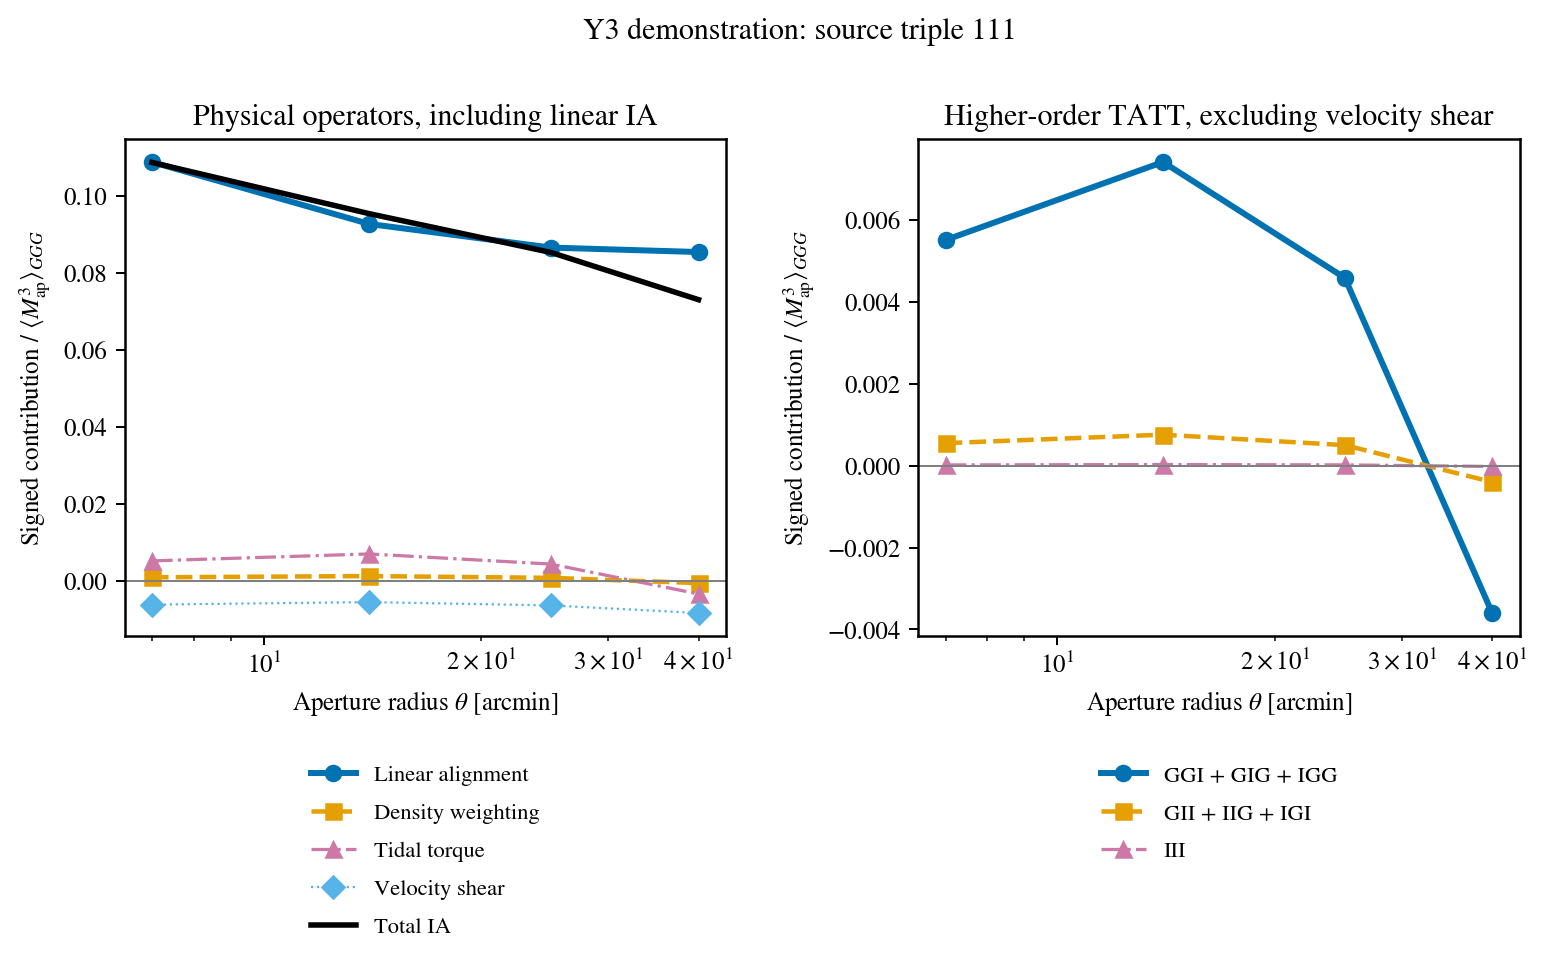

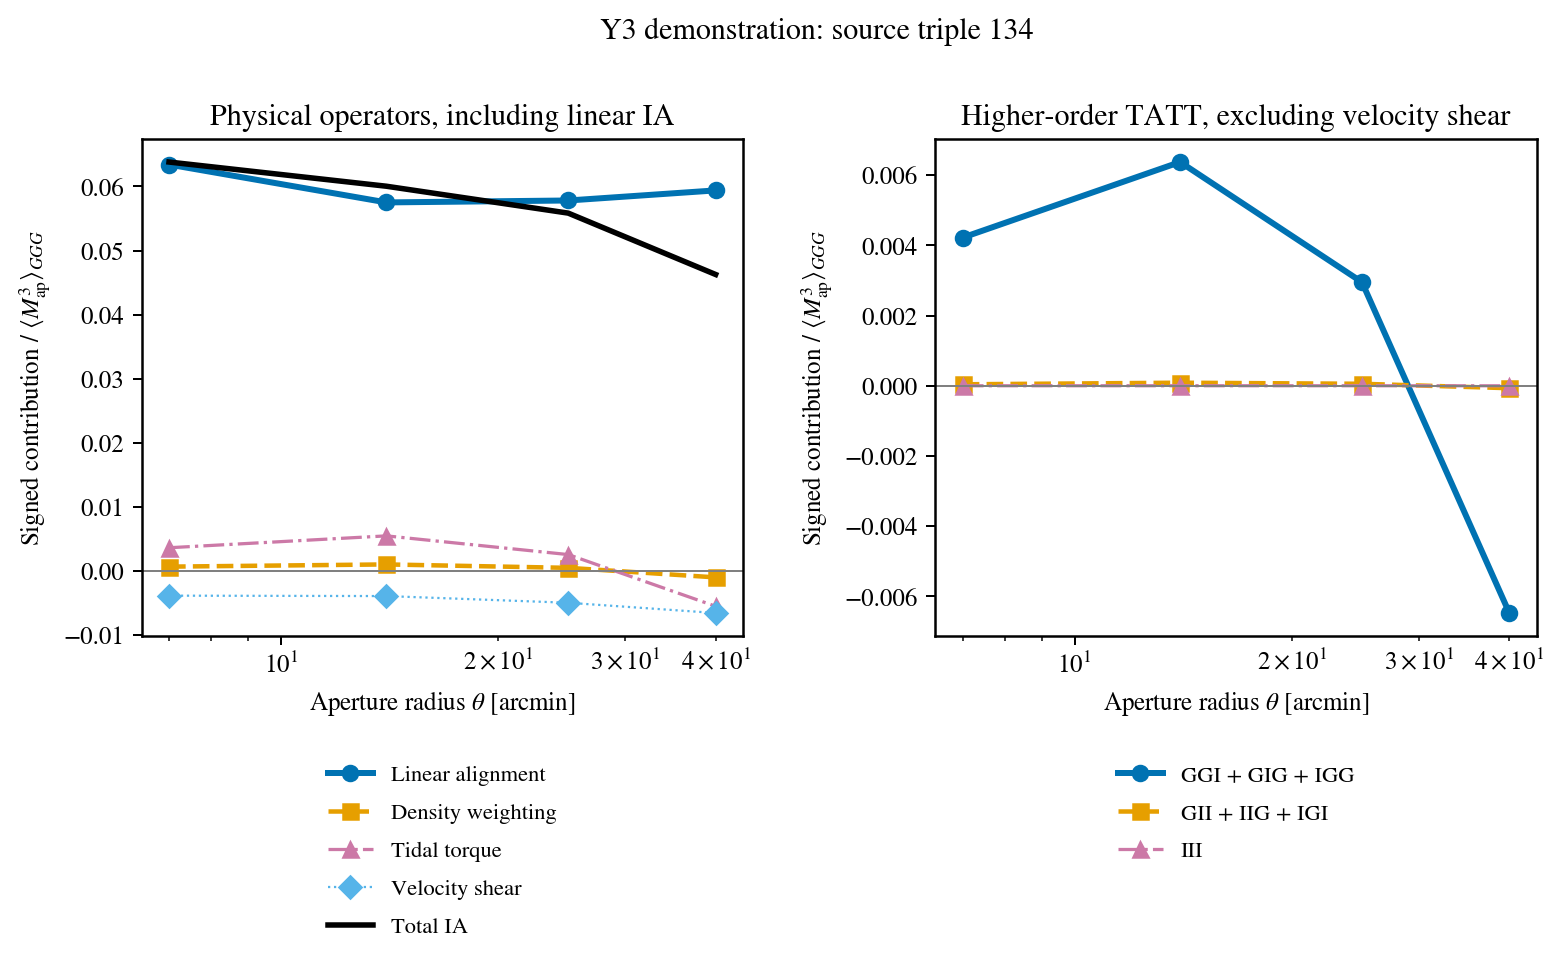

In [4]:
figures = []
output = PROJECT / "chains/ia_components"
output.mkdir(parents=True, exist_ok=True)
for triple in ((0, 0, 0), (0, 2, 3)):
    selected = np.all(report["rows"].bins == triple, axis=1)
    radii = report["rows"].angles[selected, 0] * 180.0 * 60.0 / np.pi
    order = np.argsort(radii)
    values = components["values"][:, :, selected][:, :, order]
    label = "".join(str(index + 1) for index in triple)
    figure, axes = plots.plot_ia_operator_placement(
        radius=radii[order], values=values,
        title=f"Y3 demonstration: source triple {label}",
    )
    figure.savefig(output / f"components_{label}.png", dpi=150)
    figures.append(figure)
    plt.show()


## 3. Checked invariants and remaining physical input

The implementation tests the equilateral identity
$B_{\delta\delta E}^\mathrm{residual}/P^2=-C_2/6-C_{1\delta}/2$, the
zero-amplitude limits, the ordered-leg projection, the signed interpolation
sum, and the aperture sum. It also repeats total evaluations after component
evaluations and changes the OpenMP worker count, so operator bookkeeping and
state safety are covered. These tests do not replace a resolution study at the
survey scales or a matched comparison with the original figure inputs.

The arrays keep all eight placements. `components["values"][3, 1]` picks tidal
torque in $GGI$, and `components["values"][1, 7]` picks linear alignment in
$III$; the `operators` and `placements` entries list the axes, and no
source-bin sorting happens after projection. The finite-window E-only model and
the velocity-shear manuscript/code discrepancy stay open limits.